In [93]:
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

In [94]:
sqy2h_outputs_dir = "../3_outputs/sqY2H"
metadata_outputs_dir = "../../../1_allele_collection/3_outputs"
integrative_inputs = "../../../3_integrated_assay_results/1_inputs"

In [95]:
# process metadata
metadata = pl.DataFrame(pd.read_csv(f"{metadata_outputs_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad.tsv", sep="\t"))
mut_cols = ["mutation_id_rc4", "mutation_id_cegs2", "mutation_id_edgotyping3"]
id_vars = [col for col in metadata.columns if col not in mut_cols]
# metadata = metadata.unpivot(index=id_vars, 
#                             on=mut_cols,
#                             variable_name="mutation_collection",
#                             value_name="mut_id")

priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]
metadata = metadata.select(priority_col).filter(~pl.col("mut_id").is_null()).with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id"),
    pl.col("orf_id").cast(pl.Int64).alias("orf_id")
)

In [96]:
# merge scores with metadata
scores = pl.read_csv(f"{sqy2h_outputs_dir}/5_variant_perturbation_scores_automated_summed.csv").with_columns(
    pl.col("db_orf_id").cast(pl.Int64).alias("orf_id"),
    pl.col("db_mut_id").cast(pl.Int64).alias("mut_id"),
).drop(["db_orf_id", "db_mut_id"])

scores = scores.join(metadata, on=["orf_id", "mut_id"])
# scores.write_csv(f"{sqy2h_outputs_dir}/6_variant_perturbation_scores_annotated.csv")
# scores.write_csv(f"{integrative_inputs}/ppi_scores.csv")
# scores = scores.filter(pl.col("clinvar_clnsig_clean") != "5_Others")

In [97]:
scores_pd = scores.to_pandas()
scores_pd.clinvar_clnsig_clean.value_counts()

clinvar_clnsig_clean
1_Pathogenic     239
4_VUS             91
3_Conflicting     75
5_Others          42
2_Benign          30
Name: count, dtype: int64

In [98]:
# Drop duplicates on allele_0, keeping the one with higher mut_id value
scores_dedup = scores.sort("mut_id", descending=True).unique(subset=["allele_0"], keep="first")

scores_dedup.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("allele_0").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance_normalized", "allele_0", "clinvar_clnsig_clean"])
).write_csv("../3_outputs/sqY2H/PPI_referenceSet.csv")

scores_dedup.with_columns(
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("allele_0").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/PPI_allScores.csv")

In [99]:
scores_dedup

euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,mahalanobis_distance,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,normalized_euclid_distance,normalized_mahalanobis_distance,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right
f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64
3156.433728,1216.729474,0.246205,1216.729474,1.32662,1.32662,null,4,false,0.0,949.301991,0.31126,0.39493,3725.214473,0.753795,1578.216864,null,0.165811,"""GFAP""","""Glu210Lys""","""628G>A""","""ENSG00000131095""","""CEGS2""","""5_Others""",null,null,"""GFAP_Glu210Lys""",2920,214419,"""GFAP""","""Glu210Lys""","""ENSG00000131095""","""5_Others""",null,null
4283.411906,4283.411906,0.772869,4283.411906,4.402742,4.402742,null,1,false,0.0,-4283.411906,-0.772869,null,1258.811787,0.227131,4283.411906,null,0.450025,"""AGXT""","""Ala280Val""","""839C>T""","""ENSG00000172482""","""Edgotyping3""","""2_Benign""",0.001057,2.0,"""AGXT_Ala280Val""",70497,3867,"""AGXT""","""Ala280Val""","""ENSG00000172482""","""2_Benign""",0.001057,2.0
784.508538,784.508538,0.24143,784.508538,1.31827,1.31827,null,1,false,0.0,-784.508538,-0.24143,null,2464.91899,0.75857,784.508538,null,0.082422,"""VHL""","""His150Asp""","""448C>G""","""ENSG00000134086""","""CEGS2""","""1_Pathogenic""",6.8405e-7,1.0,"""VHL_His150Asp""",13320,204006,"""VHL""","""His150Asp""","""ENSG00000134086""","""1_Pathogenic""",6.8405e-7,1.0
5254.555658,4111.530892,0.833944,4111.530892,6.022076,6.022076,null,2,false,0.5,-3691.74137,-0.664619,0.239462,818.691519,0.166056,3715.531938,null,0.390363,"""KCNJ2""","""Val295Ala""","""884T>C""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",null,2.0,"""KCNJ2_Val295Ala""",100016069,2639,"""KCNJ2""","""Val295Ala""","""ENSG00000123700""","""4_VUS""",null,2.0
4845.10926,3441.159657,0.368019,3441.159657,1.582326,1.582326,null,2,false,0.0,-3425.975967,-0.367742,0.000393,5857.183241,0.631981,3426.009613,null,0.359945,"""HPRT1""","""Pro176Leu""","""527C>T""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",null,null,"""HPRT1_Pro176Leu""",7982,202805,"""HPRT1""","""Pro176Leu""","""ENSG00000165704""","""1_Pathogenic""",null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2537.503365,-2537.503365,-0.928984,2537.503365,0.518408,0.518408,null,1,false,0.0,2537.503365,0.928984,null,5268.984447,1.928984,2537.503365,null,0.266596,"""TTR""","""Ala117Ser""","""349G>T""","""ENSG00000118271""","""CEGS2""","""1_Pathogenic""",null,2.0,"""TTR_Ala117Ser""",8999,203011,"""TTR""","""Ala117Ser""","""ENSG00000118271""","""1_Pathogenic""",null,2.0
10333.708228,387.526788,0.061718,387.526788,1.065777,1.065777,null,15,false,0.0,1740.787769,0.973954,2.652439,4818.655054,0.938282,2668.151992,null,0.280322,"""LITAF""","""Pro34Thr""","""100C>A""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,2.0,"""LITAF_Pro34Thr""",52920,2687,"""LITAF""","""Pro34Thr""","""ENSG00000189067""","""4_VUS""",0.000008,2.0
3249.863728,-3249.863728,-1.189781,3249.863728,0.456667,0.456667,null,1,false,0.0,3249.863728,1.189781,null,5981.34481,2.189781,3249.863728,null,0.341438,"""TTR""","""Val91Ala""","""272T>C""","""ENSG00000118271""","""CEGS2""","""1_Pathogenic""",null,null,"""TTR_Val91Ala""",8999,203005,"""TTR""","""Val91Ala""","""ENSG00000118271""","""1_Pathogenic""",null,null


In [100]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_bcv.log" --bandwidth "bcv" --printTransitions 
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_default.log" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_sj.log" --printTransitions --bandwidth "SJ"
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-07-29_17:15:41 INFO: Reading input 
2025-07-29_17:15:41 INFO: Calculating densties 


Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-07-29_17:15:42 INFO: Drawing LLR plot 
2025-07-29_17:15:42 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-07-29_17:15:42 INFO: Category transitions:  
0.503 : none -> patho.support
0.593 : patho.support -> patho.moderate
0.632 : patho.moderate -> patho.strong
0.645 : patho.strong -> patho.vstrong
2025-07-29_17:15:42 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-07-29_17:15:42 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv.csv 
2025-07-29_17:15:42 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

2025-07-29_17:15:46 INFO: Reading input 
2025-07-29_17:15:46 INFO: Calculating densties 
2025-07-29_17:15:47 INFO: Drawing LLR plot 
2025-07-29_17:15:47 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-07-29_17:15:48 INFO: Category transitions:  
0.526 : none -> patho.support
0.565 : patho.support -> patho.moderate
0.596 : patho.moderate -> patho.strong
0.607 : patho.strong -> patho.vstrong
2025-07-29_17:15:48 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-07-29_17:15:48 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd.csv 
2025-07-29_17:15:48 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-07-29_17:15:48 INFO: Reading input 
2025-07-29_17:15:48 INFO: Calculating densties 
2025-07-29_17:15:49 INFO: Drawing LLR plot 
2025-07-29_17:15:49 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-07-29_17:15:50 INFO: Category transitions:  
0.513 : none -> patho.support
0.547 : patho.support -> patho.moderate
0.579 : patho.moderate -> patho.strong
0.588 : patho.strong -> patho.vstrong
2025-07-29_17:15:50 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-07-29_17:15:50 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_sj.csv 
2025-07-29_17:15:50 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-07-29_17:15:50 INFO: Reading input 
2025-07-29_17:15:50 INFO: Calculating densties 
2025-07-29_17:15:51 INFO: Drawing LLR plot 
2025-07-29_17:15:51 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-07-29_17:15:52 INFO: Category transitions:  
0.526 : none -> patho.support
0.565 : patho.support -> patho.moderate
0.596 : patho.moderate -> patho.strong
0.607 : patho.strong -> patho.vstrong
2025-07-29_17:15:52 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-07-29_17:15:52 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd.csv 
2025-07-29_17:15:52 INFO: Done! 


In [101]:
# %%bash
# # source ~/software/anaconda3/etc/profile.d/conda.sh
# conda activate py310

# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_bcv.log" --bandwidth "bcv" --printTransitions --outlierSuppression 0.2
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --outlierSuppression 0.1


# ## Non-smooth, failed bandwidth:
# ## No need to run any more
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_default.log" --printTransitions
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_sj.log" --printTransitions --bandwidth "SJ"
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions

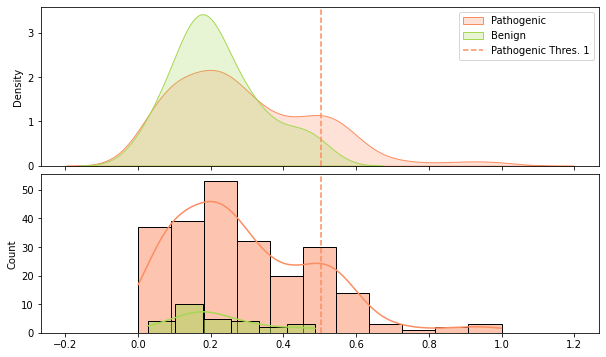

In [102]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
plt.show()

In [103]:
num_edge_filter = 1

benign_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
# print(benign_scores.shape)

path_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
# print(path_scores.shape)

vus_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
# print(vus_scores.shape)

conf_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
# print(conf_scores.shape)

print(f"With this threshold, we capture {benign_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} benign alleles at ~5% error rate, which is {benign_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}% of the benign alleles.")
print(f"With this threshold, we capture {path_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} pathogenic alleles at ~5% error rate, which is {path_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / path_scores.shape[0] * 100:.2f}% of the pathogenic alleles.")
print(f"With this threshold, we classify {vus_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} VUS and {conf_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} conflicting alleles as pathogenic at ~5% error rate, which is {vus_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}% and {conf_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}% of the VUS and conflicting alleles, respectively.")

With this threshold, we capture 0 benign alleles at ~5% error rate, which is 0.00% of the benign alleles.
With this threshold, we capture 44 pathogenic alleles at ~5% error rate, which is 18.80% of the pathogenic alleles.
With this threshold, we classify 9 VUS and 5 conflicting alleles as pathogenic at ~5% error rate, which is 9.89% and 6.67% of the VUS and conflicting alleles, respectively.


In [104]:
scores_dedup = scores_dedup.rename({"normalized_euclid_distance_normalized": "ppi_score_final_euclidean"}).with_columns(
    (pl.col("ppi_score_final_euclidean") > 0.503).alias("ppi_hit")
)
scores_dedup.write_csv(f"{sqy2h_outputs_dir}/6_variants_perturbation_scores_automated_annotated.csv")

In [105]:
scores_dedup

euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,mahalanobis_distance,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,normalized_euclid_distance,normalized_mahalanobis_distance,ppi_score_final_euclidean,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right,ppi_hit
f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64,bool
3156.433728,1216.729474,0.246205,1216.729474,1.32662,1.32662,null,4,false,0.0,949.301991,0.31126,0.39493,3725.214473,0.753795,1578.216864,null,0.165811,"""GFAP""","""Glu210Lys""","""628G>A""","""ENSG00000131095""","""CEGS2""","""5_Others""",null,null,"""GFAP_Glu210Lys""",2920,214419,"""GFAP""","""Glu210Lys""","""ENSG00000131095""","""5_Others""",null,null,false
4283.411906,4283.411906,0.772869,4283.411906,4.402742,4.402742,null,1,false,0.0,-4283.411906,-0.772869,null,1258.811787,0.227131,4283.411906,null,0.450025,"""AGXT""","""Ala280Val""","""839C>T""","""ENSG00000172482""","""Edgotyping3""","""2_Benign""",0.001057,2.0,"""AGXT_Ala280Val""",70497,3867,"""AGXT""","""Ala280Val""","""ENSG00000172482""","""2_Benign""",0.001057,2.0,false
784.508538,784.508538,0.24143,784.508538,1.31827,1.31827,null,1,false,0.0,-784.508538,-0.24143,null,2464.91899,0.75857,784.508538,null,0.082422,"""VHL""","""His150Asp""","""448C>G""","""ENSG00000134086""","""CEGS2""","""1_Pathogenic""",6.8405e-7,1.0,"""VHL_His150Asp""",13320,204006,"""VHL""","""His150Asp""","""ENSG00000134086""","""1_Pathogenic""",6.8405e-7,1.0,false
5254.555658,4111.530892,0.833944,4111.530892,6.022076,6.022076,null,2,false,0.5,-3691.74137,-0.664619,0.239462,818.691519,0.166056,3715.531938,null,0.390363,"""KCNJ2""","""Val295Ala""","""884T>C""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",null,2.0,"""KCNJ2_Val295Ala""",100016069,2639,"""KCNJ2""","""Val295Ala""","""ENSG00000123700""","""4_VUS""",null,2.0,false
4845.10926,3441.159657,0.368019,3441.159657,1.582326,1.582326,null,2,false,0.0,-3425.975967,-0.367742,0.000393,5857.183241,0.631981,3426.009613,null,0.359945,"""HPRT1""","""Pro176Leu""","""527C>T""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",null,null,"""HPRT1_Pro176Leu""",7982,202805,"""HPRT1""","""Pro176Leu""","""ENSG00000165704""","""1_Pathogenic""",null,null,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2537.503365,-2537.503365,-0.928984,2537.503365,0.518408,0.518408,null,1,false,0.0,2537.503365,0.928984,null,5268.984447,1.928984,2537.503365,null,0.266596,"""TTR""","""Ala117Ser""","""349G>T""","""ENSG00000118271""","""CEGS2""","""1_Pathogenic""",null,2.0,"""TTR_Ala117Ser""",8999,203011,"""TTR""","""Ala117Ser""","""ENSG00000118271""","""1_Pathogenic""",null,2.0,false
10333.708228,387.526788,0.061718,387.526788,1.065777,1.065777,null,15,false,0.0,1740.787769,0.973954,2.652439,4818.655054,0.938282,2668.151992,null,0.280322,"""LITAF""","""Pro34Thr""","""100C>A""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,2.0,"""LITAF_Pro34Thr""",52920,2687,"""LITAF""","""Pro34Thr""","""ENSG00000189067""","""4_VUS""",0.000008,2.0,false
3249.863728,-3249.863728,-1.189781,3249.863728,0.456667,0.456667,null,1,false,0.0,3249.863728,1.189781,null,5981.34481,2.189781,3249.863728,null,0.341438,"""TTR""","""Val91Ala""","""272T>C""","""ENSG00000118271""","""CEGS2""","""1_Pathogenic""",null,null,"""TTR_Val91Ala""",8999,203005,"""TTR""","""Val91Ala""","""ENSG00000118271""","""1_Pathogenic""",null,null,false
